# **AE 611 - Assignment on 2D Vortex Panel Method**
<h3 align="RIGHT">Submitted by: Kalyana Raama Bheema<h3>

# 1. Vortex Panel Methods
## 1.1 Aim
The aim of this assignment is to build and test two 2D vortex panel methods and use them to predict the aerodynamic characteristics of a circular cylinder and of airfoils.

The objectives are:
1. Write the algorithms for the **constant-strength** and the **linear-strength** vortex panel methods.
2. Implement them in Python as `vortex_panel_method_0()` and `vortex_panel_method_1()`.
3. Verify both on a **circular cylinder** (exact solution known) and study convergence.
4. Verify both on a **symmetric (NACA 0012)** and a **cambered (NACA 4412)** airfoil; study the effect of the number of panels and of the panel-length distribution.
5. Predict $C_l$, $C_m$ and the $C_p$ distributions of NACA 0012 and NACA 4412.
6. Show that the predictive capability of panel methods falls as the airfoil gets thicker.
7. List the references and the use of AI.

## 1.2 Introduction
A panel method replaces the body surface by many short straight lines called **panels**. Each panel carries a vortex sheet. The strengths of these sheets are chosen so that:
- **no flow passes through the surface** (no-penetration condition at the midpoint of every panel), and
- **the flow leaves the sharp trailing edge smoothly** (Kutta condition).

Once the strengths are known, the surface velocity gives the pressure coefficient $C_p$, and the total circulation gives the lift $C_l$. Only the surface has to be discretised, not the whole flow field (_Katz & Plotkin, 2001_).

The flow is assumed **steady, 2D, incompressible, inviscid and irrotational**. Viscous effects (boundary layer, separation, stall, drag) are therefore not modelled.

Two types of panels are compared:
- **Constant-strength panels:** one unknown $\gamma_j$ per panel; $\gamma$ is constant along the panel.
- **Linear-strength panels** (_Liu, 2018_): one unknown per **node**; $\gamma$ varies linearly along each panel and is continuous from panel to panel.

## 1.3 Conventions
- Boundary points $(x_1,y_1),\dots,(x_{N+1},y_{N+1})$ are ordered **clockwise, starting at the trailing edge (TE)**: lower surface TE $\to$ LE, then upper surface LE $\to$ TE. Panel $j$ joins node $j$ to node $j+1$, giving $N$ panels.
- $\theta_j=\operatorname{atan2}(y_{j+1}-y_j,\ x_{j+1}-x_j)$ is the panel angle. The outward normal is $(-\sin\theta_j,\cos\theta_j)$.
- The **control point** of each panel is its midpoint.
- $\gamma>0$ is a **clockwise** vortex sheet, so positive circulation gives positive lift.
- The solver works with the non-dimensional strength $\gamma'=\gamma/(2\pi V_\infty)$, as in _Kuethe & Chow (1998)_ and _Liu (2018)_.
- Chord $c=1$, $V_\infty=1$. $C_m$ is taken about the quarter chord, nose-up positive.

## 1.4 Influence coefficients (shared by both methods)
For control point $i$ and panel $j$ (from node $j$, length $S_j$), with $dx=x_i-X_j$ and $dy=y_i-Y_j$:
$$
\begin{aligned}
A &= -dx\cos\theta_j-dy\sin\theta_j, \qquad B = dx^2+dy^2,\\
C &= \sin(\theta_i-\theta_j), \qquad D=\cos(\theta_i-\theta_j), \qquad E = dx\sin\theta_j-dy\cos\theta_j,\\
F &= \ln\!\Big(1+\frac{S_j^2+2AS_j}{B}\Big), \qquad G=\operatorname{atan2}(ES_j,\ B+AS_j),\\
P &= dx\sin(\theta_i-2\theta_j)+dy\cos(\theta_i-2\theta_j), \qquad Q=dx\cos(\theta_i-2\theta_j)-dy\sin(\theta_i-2\theta_j).
\end{aligned}
$$
The normal ($n$) and tangential ($t$) velocity at point $i$ caused by a unit strength at the **start (1)** and **end (2)** of panel $j$ are (_Liu, 2018_, Eqs. 11–21):
$$
\begin{aligned}
C_{n2}&=D+\tfrac12\,QF/S_j-(AC+DE)\,G/S_j, & C_{n1}&=\tfrac12\,DF+CG-C_{n2},\\
C_{t2}&=C+\tfrac12\,PF/S_j+(AD-CE)\,G/S_j, & C_{t1}&=\tfrac12\,CF-DG-C_{t2}.
\end{aligned}
$$
On the panel itself ($i=j$): $C_{n1}=-1,\ C_{n2}=1,\ C_{t1}=C_{t2}=\pi/2$.

## 1.5 Algorithm A: constant-strength vortex panels (`vortex_panel_method_0()`)
Unknowns: $\gamma'_1,\dots,\gamma'_N$ (one per panel).
1. Generate the $N+1$ boundary points (clockwise from the TE).
2. For every panel compute the control point, length $S_j$ and angle $\theta_j$.
3. For every pair $(i,j)$ compute $C_{n1},C_{n2},C_{t1},C_{t2}$ (Section 1.4).
4. A constant panel is a linear panel with equal end strengths, so add the two ends:
   $A_{ij}=C_{n1,ij}+C_{n2,ij}$ (normal), $\ T_{ij}=C_{t1,ij}+C_{t2,ij}$ (tangential).
5. No-penetration at every control point: $\displaystyle\sum_j A_{ij}\gamma'_j=\sin(\theta_i-\alpha),\quad i=1\dots N$.
6. Kutta condition: add the row $\gamma'_1+\gamma'_N=0$. This gives $N+1$ equations for $N$ unknowns, which are solved in the **least-squares** sense, ignoring singular values smaller than $10^{-3}$ times the largest (`np.linalg.lstsq(A, b, rcond=1e-3)`).
   *Why the cut-off:* constant-strength panels allow a spurious **zig-zag** pattern $\gamma'=+,-,+,-,\dots$ that produces almost no normal velocity at the control points. It shows up as a very small singular value of the matrix. If it is kept, $C_p$ oscillates from panel to panel (badly for even $N$, and for some odd $N$ such as 41). The cut-off removes that mode only when it is nearly singular and leaves the physical solution unchanged.
7. Tangential velocity: $V_{t,i}/V_\infty=\cos(\theta_i-\alpha)+\sum_j T_{ij}\gamma'_j$.
8. Pressure coefficient: $C_{p,i}=1-(V_{t,i}/V_\infty)^2$.
9. Lift from circulation: $C_l = 4\pi\sum_j\gamma'_jS_j/c$; lift and moment also by summing the pressure force on each panel.

## 1.6 Algorithm B: linear-strength vortex panels (`vortex_panel_method_1()`, _Liu, 2018_)
Unknowns: nodal strengths $\gamma'_1,\dots,\gamma'_{N+1}$, with $\gamma'$ varying linearly on each panel.
1. Generate the boundary points and panel data as in Algorithm A (any $N$ works).
2. Compute $C_{n1},C_{n2},C_{t1},C_{t2}$ for every $(i,j)$.
3. Each node gets the "end 1" effect of panel $j$ and the "end 2" effect of panel $j-1$:
   $$A_{i1}=C_{n1,i1},\qquad A_{ij}=C_{n1,ij}+C_{n2,i(j-1)}\ (j=2\dots N),\qquad A_{i,N+1}=C_{n2,iN}.$$
   The tangential matrix $T$ is built the same way from $C_{t1},C_{t2}$.
4. No-penetration at the $N$ control points: $\displaystyle\sum_{j=1}^{N+1}A_{ij}\gamma'_j=\sin(\theta_i-\alpha)$.
5. Kutta condition (row $N+1$): $\gamma'_1+\gamma'_{N+1}=0$. The system is now **square** and solved directly.
6. Tangential velocity at the control points (Liu): $V_{t,i}/V_\infty=\cos(\theta_i-\alpha)+\sum_jT_{ij}\gamma'_j$, and $C_{p,i}=1-(V_{t,i}/V_\infty)^2$.
7. Because the fluid inside the body is at rest, the surface speed also equals the local sheet strength. So $C_p$ can also be found **at each node**: $C_{p,j}=1-(2\pi\gamma'_j)^2$. (This turns out to be much more accurate; see Section 3.)
8. Lift from circulation (exact integral of the linear sheet): $C_l=2\pi\sum_j(\gamma'_j+\gamma'_{j+1})S_j/c$.

# 2. Python Implementation
## 2.1 Generation of geometry
- `cylinder_geometry(N, R)` returns $N+1$ points on a circle, clockwise from $(R,0)$.
- `naca4_geometry(code, N, spacing)` returns $N+1$ points of a NACA 4-digit airfoil (chord $=1$), ordered TE $\to$ lower $\to$ LE $\to$ upper $\to$ TE.
  With `spacing='cosine'` the points are $x=\tfrac12(1-\cos\beta)$ for equal steps in $\beta$ (bunched at LE and TE). With `spacing='uniform'` they are equally spaced in $x$.

The thickness distribution is (_Abbott & von Doenhoff, 1959_):
$$y_t=5t\,(0.2969\sqrt{x}-0.1260x-0.3516x^2+0.2843x^3-0.1036x^4).$$
The last coefficient $-0.1036$ (instead of $-0.1015$) gives a **closed** trailing edge, which is needed for the Kutta condition. The thickness is added perpendicular to the camber line.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (8, 5), "font.size": 11, "axes.grid": True, "grid.alpha": 0.3})

In [3]:
def cylinder_geometry(N, R=1.0):
    # N+1 boundary points on a circle of radius R, clockwise, starting at (R, 0)
    phi = np.linspace(0, 2*np.pi, N + 1)
    return R*np.cos(phi), -R*np.sin(phi)


def naca4_geometry(code, N, spacing="cosine"):
    # N+1 boundary points of a NACA 4-digit airfoil, chord = 1
    # Order: TE -> lower surface -> LE -> upper surface -> TE (clockwise)
    m = int(code[0]) / 100       # maximum camber
    p = int(code[1]) / 10        # position of maximum camber
    t = int(code[2:]) / 100      # thickness

    def x_points(n):             # n panels -> n+1 points from x = 0 to 1
        if spacing == "cosine":
            return 0.5*(1 - np.cos(np.linspace(0, np.pi, n + 1)))
        return np.linspace(0, 1, n + 1)

    def surface(x, sign):        # sign = +1 upper, -1 lower
        yt = 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1036*x**4)
        yc, dyc = np.zeros_like(x), np.zeros_like(x)
        if m > 0:
            yc  = np.where(x < p, m/p**2*(2*p*x - x**2), m/(1-p)**2*((1 - 2*p) + 2*p*x - x**2))
            dyc = np.where(x < p, 2*m/p**2*(p - x),      2*m/(1-p)**2*(p - x))
        th = np.arctan(dyc)
        return x - sign*yt*np.sin(th), yc + sign*yt*np.cos(th)

    n_low = N // 2               # panels on the lower surface
    n_up = N - n_low             # panels on the upper surface (works for odd N too)
    xl, yl = surface(x_points(n_low), -1)
    xu, yu = surface(x_points(n_up), +1)
    xb = np.concatenate([xl[::-1], xu[1:]])
    yb = np.concatenate([yl[::-1], yu[1:]])
    return xb, yb

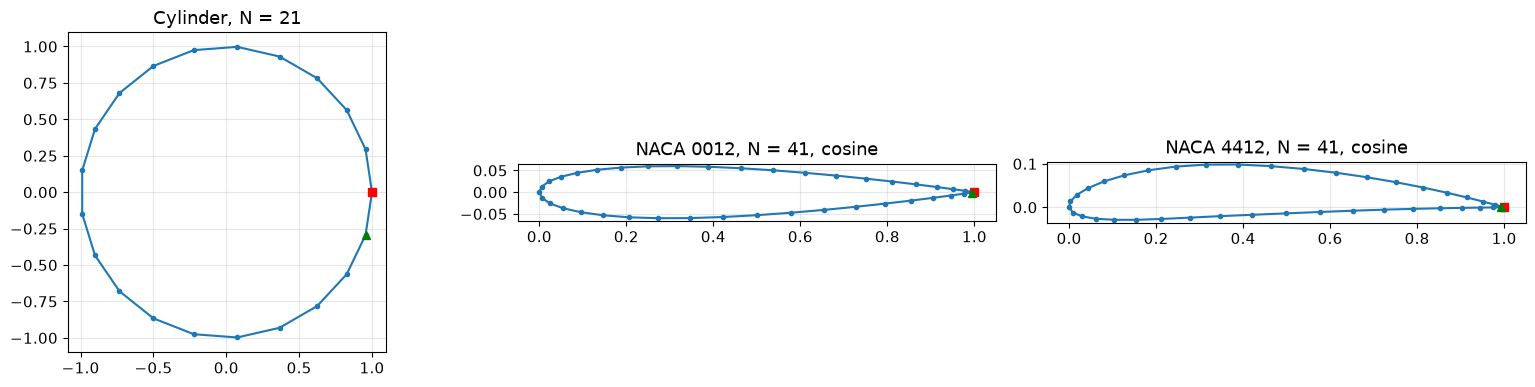

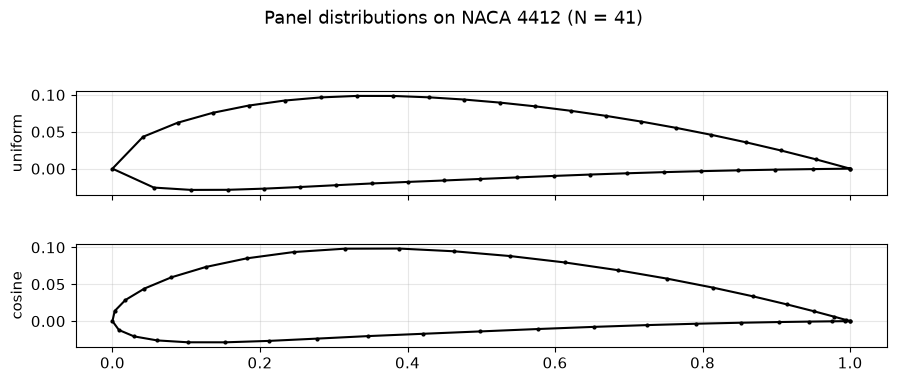

In [4]:
# Plotting the geometries (red square = node 1 at the trailing edge)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (name, (xb, yb)) in zip(ax, {
        "Cylinder, N = 21": cylinder_geometry(21),
        "NACA 0012, N = 41, cosine": naca4_geometry("0012", 41),
        "NACA 4412, N = 41, cosine": naca4_geometry("4412", 41)}.items()):
    a.plot(xb, yb, "o-", ms=3); a.plot(xb[0], yb[0], "rs"); a.plot(xb[1], yb[1], "g^")
    a.set_aspect("equal"); a.set_title(name)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
for a, sp in zip(ax, ["uniform", "cosine"]):
    xb, yb = naca4_geometry("4412", 41, sp)
    a.plot(xb, yb, "k.-", ms=4); a.set_aspect("equal"); a.set_ylabel(sp)
plt.suptitle("Panel distributions on NACA 4412 (N = 41)"); plt.tight_layout(); plt.show()

## 2.2 Influence coefficients
`influence(xb, yb)` returns the panel data (control points, lengths, angles) and the four coefficient matrices $C_{n1},C_{n2},C_{t1},C_{t2}$ of Section 1.4. It is written as two simple loops so that each line can be compared with the formulas.

In [5]:
def influence(xb, yb):
    # Kuethe & Chow / Liu (2018) influence coefficients Cn1, Cn2, Ct1, Ct2
    N = len(xb) - 1
    xc = 0.5*(xb[:-1] + xb[1:])                  # control points (panel midpoints)
    yc = 0.5*(yb[:-1] + yb[1:])
    S = np.hypot(np.diff(xb), np.diff(yb))       # panel lengths
    th = np.arctan2(np.diff(yb), np.diff(xb))    # panel angles

    Cn1 = np.zeros((N, N)); Cn2 = np.zeros((N, N))
    Ct1 = np.zeros((N, N)); Ct2 = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            if i == j:                           # self-influence
                Cn1[i, j] = -1.0; Cn2[i, j] = 1.0
                Ct1[i, j] = np.pi/2; Ct2[i, j] = np.pi/2
                continue
            dx = xc[i] - xb[j]
            dy = yc[i] - yb[j]
            A = -dx*np.cos(th[j]) - dy*np.sin(th[j])
            B = dx**2 + dy**2
            C = np.sin(th[i] - th[j])
            D = np.cos(th[i] - th[j])
            E = dx*np.sin(th[j]) - dy*np.cos(th[j])
            F = np.log(1 + (S[j]**2 + 2*A*S[j]) / B)
            G = np.arctan2(E*S[j], B + A*S[j])
            P = dx*np.sin(th[i] - 2*th[j]) + dy*np.cos(th[i] - 2*th[j])
            Q = dx*np.cos(th[i] - 2*th[j]) - dy*np.sin(th[i] - 2*th[j])
            Cn2[i, j] = D + 0.5*Q*F/S[j] - (A*C + D*E)*G/S[j]
            Cn1[i, j] = 0.5*D*F + C*G - Cn2[i, j]
            Ct2[i, j] = C + 0.5*P*F/S[j] + (A*D - C*E)*G/S[j]
            Ct1[i, j] = 0.5*C*F - D*G - Ct2[i, j]
    panels = {"xc": xc, "yc": yc, "S": S, "theta": th}
    return panels, Cn1, Cn2, Ct1, Ct2

## 2.3 The two solvers
Both functions take the same arguments and return a dictionary.

| Argument / output | Meaning |
|---|---|
| `xb, yb` | $N+1$ boundary points, clockwise, starting at the trailing edge |
| `alpha_deg` | angle of attack in degrees |
| returns `gamma` | vortex strengths $\gamma/V_\infty$ ($N$ panel values for method 0, $N+1$ node values for method 1) |
| returns `xc, yc` | control points (panel midpoints) |
| returns `Vt`, `Cp` | tangential velocity and pressure coefficient at the control points |
| returns `Cp_nodes` | (method 1 only) pressure coefficient at the nodes, from $C_p=1-\gamma^2$ |
| returns `Cl` | lift coefficient from the circulation (Kutta–Joukowski) |
| returns `Cl_p`, `Cm` | lift and quarter-chord moment from integrating the pressure |

The panel distribution (uniform or cosine) is chosen when the boundary points are generated, so the solvers work on any set of points. The pressure coefficient follows from Bernoulli's equation:
$$C_p=\frac{p-p_\infty}{\tfrac12\rho V_\infty^2}=1-\Big(\frac{V_t}{V_\infty}\Big)^2.$$

In [7]:
def pressure_forces(xb, pan, Cp, alpha, x_ref=0.25):
    # Sum the pressure force on every panel -> Cl and Cm about (x_ref, 0)
    c = xb.max() - xb.min()
    S, th = pan["S"], pan["theta"]
    nx, ny = -np.sin(th), np.cos(th)            # outward normals
    Fx = np.sum(-Cp*nx*S) / c
    Fy = np.sum(-Cp*ny*S) / c
    Cl = Fy*np.cos(alpha) - Fx*np.sin(alpha)    # lift is normal to the free stream
    Cm = -np.sum((pan["xc"] - x_ref)*(-Cp*ny*S) - pan["yc"]*(-Cp*nx*S)) / c**2
    return Cl, Cm


def vortex_panel_method_0(xb, yb, alpha_deg):
    # Constant-strength vortex panel method
    a = np.radians(alpha_deg)
    pan, Cn1, Cn2, Ct1, Ct2 = influence(xb, yb)
    th, S = pan["theta"], pan["S"]
    N = len(S)

    A = Cn1 + Cn2                                # constant panel = equal end strengths
    T = Ct1 + Ct2
    b = np.sin(th - a)
    kutta = np.zeros(N); kutta[0] = kutta[-1] = 1.0   # gamma_1 + gamma_N = 0
    A = np.vstack([A, kutta]); b = np.append(b, 0.0)  # N+1 equations, N unknowns

    # Least squares; rcond=1e-3 ignores the nearly-singular zig-zag mode
    g = np.linalg.lstsq(A, b, rcond=1e-3)[0]     # g = gamma / (2 pi V_inf)

    Vt = np.cos(th - a) + T @ g
    Cp = 1 - Vt**2
    c = xb.max() - xb.min()
    Cl = 4*np.pi*np.sum(g*S) / c                # Kutta-Joukowski
    Cl_p, Cm = pressure_forces(xb, pan, Cp, a)
    return {"gamma": 2*np.pi*g, "xc": pan["xc"], "yc": pan["yc"], "Vt": Vt, "Cp": Cp,
            "Cl": Cl, "Cl_p": Cl_p, "Cm": Cm}


def vortex_panel_method_1(xb, yb, alpha_deg):
    # Linear-strength vortex panel method (Liu, 2018)
    a = np.radians(alpha_deg)
    pan, Cn1, Cn2, Ct1, Ct2 = influence(xb, yb)
    th, S = pan["theta"], pan["S"]
    N = len(S)

    A = np.zeros((N + 1, N + 1)); T = np.zeros((N, N + 1))
    A[:N, :N] += Cn1; A[:N, 1:] += Cn2           # node j: end 1 of panel j, end 2 of panel j-1
    T[:, :N]  += Ct1; T[:, 1:]  += Ct2
    A[N, 0] = A[N, N] = 1.0                      # Kutta: gamma_1 + gamma_(N+1) = 0
    b = np.append(np.sin(th - a), 0.0)

    g = np.linalg.solve(A, b)                    # square system
    Vt = np.cos(th - a) + T @ g                  # Liu: velocity at control points
    Cp = 1 - Vt**2
    Cp_nodes = 1 - (2*np.pi*g)**2                # surface speed = |gamma| at the nodes
    c = xb.max() - xb.min()
    Cl = 2*np.pi*np.sum((g[:-1] + g[1:])*S) / c  # exact integral of the linear sheet
    Cl_p, Cm = pressure_forces(xb, pan, 0.5*(Cp_nodes[:-1] + Cp_nodes[1:]), a)
    return {"gamma": 2*np.pi*g, "xc": pan["xc"], "yc": pan["yc"], "Vt": Vt, "Cp": Cp,
            "Cp_nodes": Cp_nodes, "Cl": Cl, "Cl_p": Cl_p, "Cm": Cm}

In [8]:
# Quick test: both methods on NACA 4412 at 8 deg with 161 panels
xb, yb = naca4_geometry("4412", 161)
for name, f in [("method 0 (constant)", vortex_panel_method_0), ("method 1 (linear)", vortex_panel_method_1)]:
    r = f(xb, yb, 8.0)
    print(f"{name}: Cl (circulation) = {r['Cl']:.4f},  Cl (pressure) = {r['Cl_p']:.4f},  Cm_c/4 = {r['Cm']:.4f}")

method 0 (constant): Cl (circulation) = 1.4820,  Cl (pressure) = 1.4749,  Cm_c/4 = -0.1237
method 1 (linear): Cl (circulation) = 1.4757,  Cl (pressure) = 1.4754,  Cm_c/4 = -0.1239


In [9]:
# Small helper for the log-log convergence plots: label the x-axis with the actual N values
from matplotlib.ticker import NullFormatter
def label_N(ax, Ns):
    ax.set_xticks(Ns); ax.set_xticklabels([str(n) for n in Ns]); ax.xaxis.set_minor_formatter(NullFormatter())

# 3. Verification for circular cylinder
## 3.1 Analytical solution
For a cylinder without circulation the surface speed is $V_\theta=-2V_\infty\sin\theta$, so
$$C_p=1-4\sin^2\theta,\qquad C_l=0.$$
The cylinder has no sharp trailing edge. The Kutta row $\gamma_1+\gamma_N=0$ (or $\gamma_1+\gamma_{N+1}=0$) then simply fixes the circulation to zero at the point $(R,0)$, which agrees with the symmetric exact flow, so the same solver functions are used unchanged.

The error is measured against the exact $C_p$ at the polar angle of each point:
$$E_{max}=\max_i|C_{p,i}-C_{p,i}^{exact}|,\qquad\text{observed order } p=\log_2\!\big(E_N/E_{2N}\big).$$
$N=15$ to $255$ panels, $\alpha=0^\circ$.

In [10]:
def cyl_errors(N):
    # Max Cp error on an N-panel cylinder for: method 0, method 1 (Liu, midpoints), method 1 (nodes)
    xb, yb = cylinder_geometry(N)
    r0 = vortex_panel_method_0(xb, yb, 0.0)
    r1 = vortex_panel_method_1(xb, yb, 0.0)
    th_mid = np.arctan2(r0["yc"], r0["xc"])
    th_node = np.arctan2(yb, xb)
    e0 = np.abs(r0["Cp"] - (1 - 4*np.sin(th_mid)**2)).max()
    e1m = np.abs(r1["Cp"] - (1 - 4*np.sin(th_mid)**2)).max()
    e1n = np.abs(r1["Cp_nodes"] - (1 - 4*np.sin(th_node)**2)).max()
    return e0, e1m, e1n, max(abs(r0["Cl"]), abs(r1["Cl"]))

Ns = [15, 31, 63, 127, 255]
E = np.array([cyl_errors(N) for N in Ns])
print(f"{'N':>5} | {'method 0':>10} | {'method 1 (Liu, midpts)':>22} | {'method 1 (nodes)':>16} | {'max |Cl|':>9}")
for N, e in zip(Ns, E):
    print(f"{N:5d} | {e[0]:10.2e} | {e[1]:22.2e} | {e[2]:16.2e} | {e[3]:9.1e}")
print("\nObserved order, method 1 (Liu, midpoints):", [round(np.log2(E[k-1, 1]/E[k, 1]), 2) for k in range(1, len(Ns))])
print("Observed order, method 1 (nodes)        :", [round(np.log2(E[k-1, 2]/E[k, 2]), 2) for k in range(1, len(Ns))])

    N |   method 0 | method 1 (Liu, midpts) | method 1 (nodes) |  max |Cl|
   15 |   1.11e-14 |               4.11e-01 |         5.47e-03 |   7.4e-15
   31 |   1.87e-14 |               1.90e-01 |         6.94e-04 |   6.3e-15
   63 |   4.49e-14 |               9.07e-02 |         8.72e-05 |   1.0e-14
  127 |   1.92e-13 |               4.43e-02 |         1.09e-05 |   3.0e-14
  255 |   4.57e-13 |               2.19e-02 |         1.36e-06 |   3.5e-14

Observed order, method 1 (Liu, midpoints): [np.float64(1.12), np.float64(1.06), np.float64(1.03), np.float64(1.02)]
Observed order, method 1 (nodes)        : [np.float64(2.98), np.float64(2.99), np.float64(3.0), np.float64(3.0)]


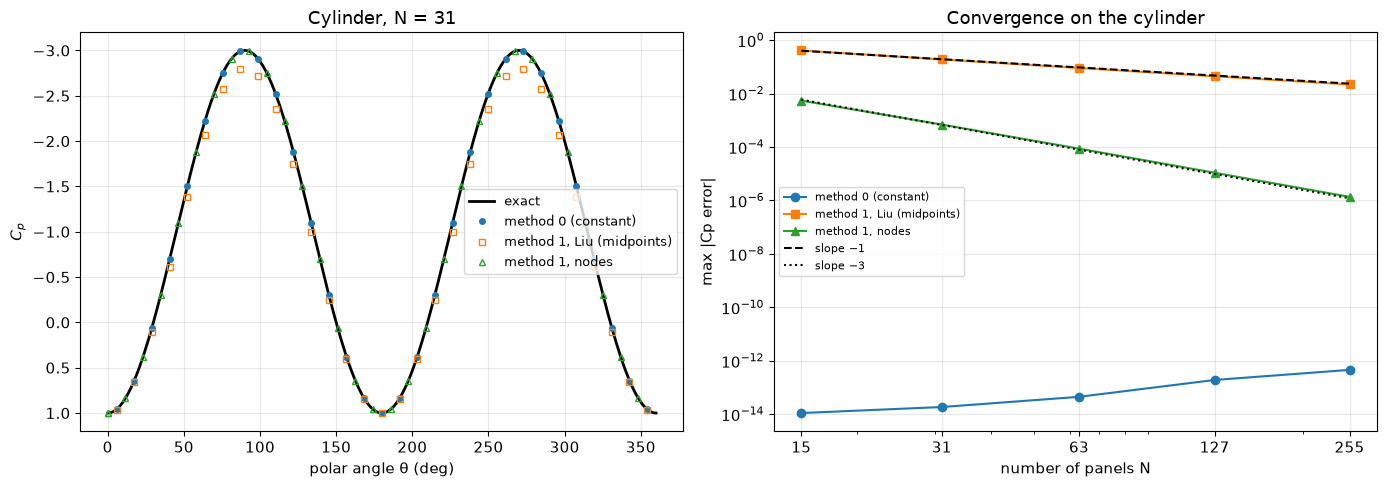

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
xb, yb = cylinder_geometry(31)
r0 = vortex_panel_method_0(xb, yb, 0.0); r1 = vortex_panel_method_1(xb, yb, 0.0)
deg = lambda x, y: np.degrees(np.arctan2(y, x) % (2*np.pi))
t = np.linspace(0, 2*np.pi, 400)
ax[0].plot(np.degrees(t), 1 - 4*np.sin(t)**2, "k", lw=2, label="exact")
ax[0].plot(deg(r0["xc"], r0["yc"]), r0["Cp"], "o", ms=4, label="method 0 (constant)")
ax[0].plot(deg(r1["xc"], r1["yc"]), r1["Cp"], "s", ms=5, mfc="none", label="method 1, Liu (midpoints)")
ax[0].plot(deg(xb, yb), r1["Cp_nodes"], "^", ms=5, mfc="none", label="method 1, nodes")
ax[0].set(xlabel="polar angle θ (deg)", ylabel="$C_p$", title="Cylinder, N = 31"); ax[0].invert_yaxis(); ax[0].legend(fontsize=9)

ax[1].loglog(Ns, E[:, 0], "o-", label="method 0 (constant)")
ax[1].loglog(Ns, E[:, 1], "s-", label="method 1, Liu (midpoints)")
ax[1].loglog(Ns, E[:, 2], "^-", label="method 1, nodes")
ax[1].loglog(Ns, 6/np.array(Ns), "k--", label="slope −1")
ax[1].loglog(Ns, 20/np.array(Ns)**3, "k:", label="slope −3")
label_N(ax[1], Ns)
ax[1].set(xlabel="number of panels N", ylabel="max |Cp error|", title="Convergence on the cylinder"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3.2 Result discussion for circular cylinder
- **Lift:** both methods give $C_l\approx0$ (below $2\times10^{-14}$), as expected for the non-lifting cylinder.
- **Method 0 (constant):** the error is at round-off level ($10^{-14}$–$10^{-13}$) for every $N$. This is a special result caused by the symmetry of the circle (every panel sees the same picture). It does not mean the method is exact in general; the airfoil tests in Section 4 show normal convergence.
- **Method 1, $C_p$ from $V_t$ at the control points (Liu's way):** only **first-order** convergence (observed order $\approx1.0$; the error halves each time $N$ doubles). The control point lies on the flat panel, slightly *inside* the true circle, so the velocity there is not exactly the surface velocity.
- **Method 1, $C_p$ from $\gamma$ at the nodes:** **third-order** convergence (observed order $\approx3.0$; the error falls 8 times when $N$ doubles), from $5.5\times10^{-3}$ at $N=15$ to $1.4\times10^{-6}$ at $N=255$. So the nodal strengths of the linear method are very accurate, and $C_p=1-\gamma^2$ at the nodes is the better way to read the pressure. This value is used for the linear method in the rest of the notebook.
- The pressure coefficient is the quantity most sensitive to the discretisation; lift converges much faster.

# 4. Verification for airfoils
The symmetric airfoil is the **NACA 0012** ($t/c=12\%$) and the cambered airfoil is the **NACA 4412** ($m=4\%$, $p=40\%$, $t/c=12\%$), the airfoil studied by _Liu (2018)_. Both are tested at $\alpha=5^\circ$.

**Set-up:** NACA airfoils have no exact solution, so a **reference** is computed with the linear method on a very fine mesh ($N=1601$, cosine spacing). Each coarser result is compared with this reference.


In [12]:
ALPHA = 5.0
ref = {}
for code_ in ["0012", "4412"]:
    r = vortex_panel_method_1(*naca4_geometry(code_, 1601, "cosine"), ALPHA)
    ref[code_] = r
    print(f"NACA {code_}, alpha = {ALPHA} deg, reference (N = 1601, cosine): Cl = {r['Cl']:.5f}, "
          f"Cm_c/4 = {r['Cm']:.4f}, Cp_min = {r['Cp_nodes'].min():.3f}")

NACA 0012, alpha = 5.0 deg, reference (N = 1601, cosine): Cl = 0.60302, Cm_c/4 = -0.0068, Cp_min = -2.064
NACA 4412, alpha = 5.0 deg, reference (N = 1601, cosine): Cl = 1.11912, Cm_c/4 = -0.1186, Cp_min = -1.787


## 4.1 Effect of the number of panels (cosine spacing)
$C_l$ (from the circulation) is compared with the reference for $N=21$ to $321$. The upper-surface $C_p$ is also compared for increasing $N$.

airfoil method      N        Cl   |dCl| %
0012    const      21    0.6125     1.570
0012    const      41    0.6105     1.238
0012    const      81    0.6074     0.735
0012    const     161    0.6054     0.399
0012    const     321    0.6043     0.207
0012    linear     21    0.6112     1.365
0012    linear     41    0.6050     0.323
0012    linear     81    0.6035     0.086
0012    linear    161    0.6032     0.022
0012    linear    321    0.6030     0.006
4412    const      21    1.1348     1.399
4412    const      41    1.1331     1.252
4412    const      81    1.1278     0.772
4412    const     161    1.1237     0.405
4412    const     321    1.1215     0.211
4412    linear     21    1.1129     0.554
4412    linear     41    1.1176     0.132
4412    linear     81    1.1190     0.008
4412    linear    161    1.1190     0.009
4412    linear    321    1.1191     0.002


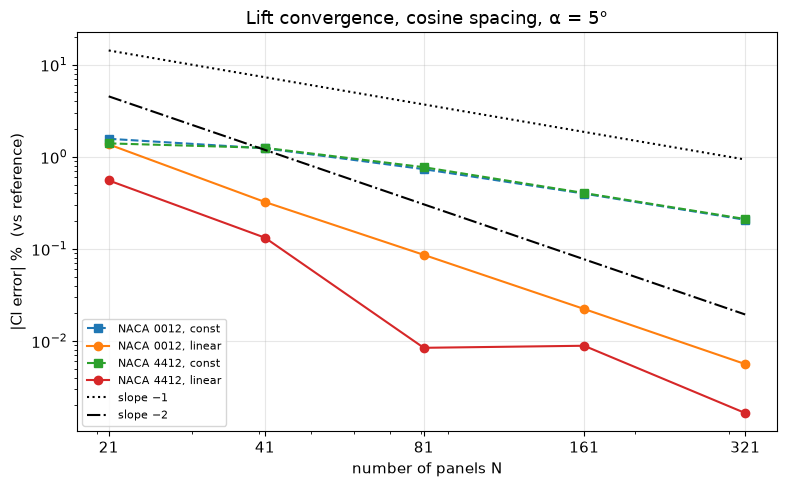

In [13]:
Ns_a = [21, 41, 81, 161, 321]
methods = [("const", vortex_panel_method_0), ("linear", vortex_panel_method_1)]
cl_err = {}
print(f"{'airfoil':8s}{'method':8s}{'N':>5s}{'Cl':>10s}{'|dCl| %':>10s}")
for code_ in ["0012", "4412"]:
    for mname, f in methods:
        errs = []
        for N in Ns_a:
            r = f(*naca4_geometry(code_, N, "cosine"), ALPHA)
            e = abs(r["Cl"] - ref[code_]["Cl"]) / ref[code_]["Cl"] * 100
            errs.append(e)
            print(f"{code_:8s}{mname:8s}{N:5d}{r['Cl']:10.4f}{e:10.3f}")
        cl_err[(code_, mname)] = errs

fig, ax = plt.subplots(figsize=(8, 5))
for (code_, mname), errs in cl_err.items():
    ax.loglog(Ns_a, errs, "o-" if mname == "linear" else "s--", label=f"NACA {code_}, {mname}")
ax.loglog(Ns_a, 300/np.array(Ns_a), "k:", label="slope −1")
ax.loglog(Ns_a, 2000/np.array(Ns_a)**2, "k-.", label="slope −2")
label_N(ax, Ns_a)
ax.set(xlabel="number of panels N", ylabel="|Cl error| %  (vs reference)", title="Lift convergence, cosine spacing, α = 5°")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

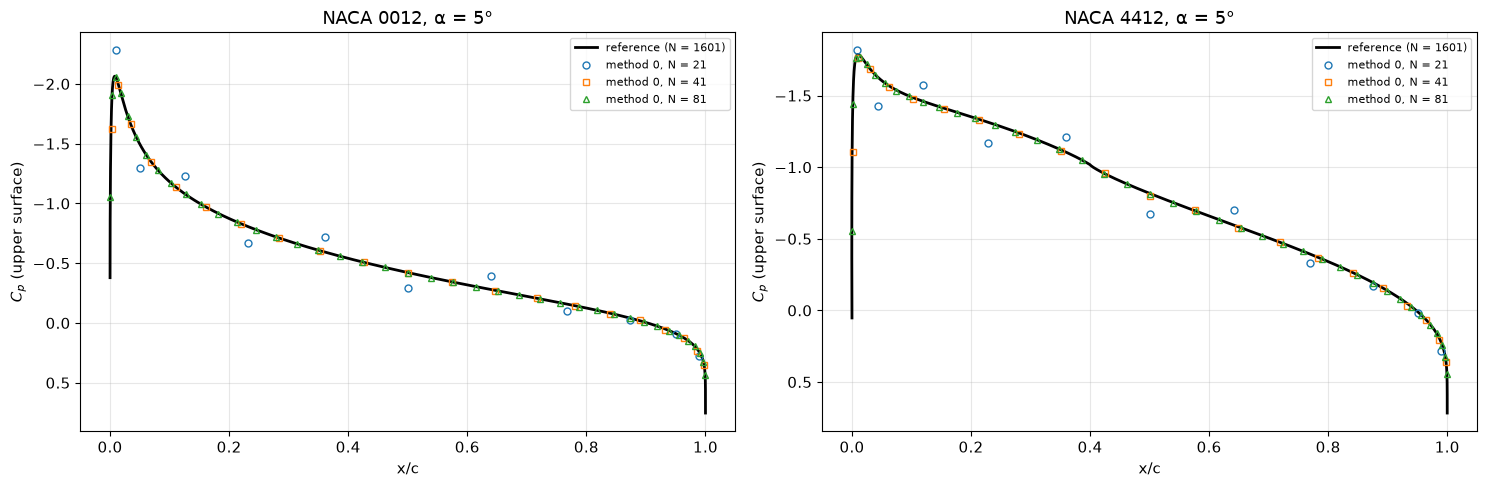

In [14]:
# Upper-surface Cp for increasing N (cosine spacing) against the reference
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for k, code_ in enumerate(["0012", "4412"]):
    xr, yr = naca4_geometry(code_, 1601)
    up = slice(800, -1)                                   # upper-surface nodes of the reference
    ax[k].plot(xr[up], ref[code_]["Cp_nodes"][up], "k-", lw=2, label="reference (N = 1601)")
    for N, mk in [(21, "o"), (41, "s"), (81, "^")]:
        xb, yb = naca4_geometry(code_, N)
        r0 = vortex_panel_method_0(xb, yb, ALPHA)
        h = N//2
        ax[k].plot(r0["xc"][h:], r0["Cp"][h:], mk, ms=5, mfc="none", label=f"method 0, N = {N}")
    ax[k].invert_yaxis(); ax[k].set(xlabel="x/c", ylabel="$C_p$ (upper surface)", title=f"NACA {code_}, α = 5°")
    ax[k].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4.2 Effect of the panel-length distribution
With **uniform** spacing the points are equally spaced in $x$: simple, but the strongly curved leading edge gets very few panels. With **cosine** spacing the panels are short near the LE and TE, where the curvature and the pressure gradients are large, and long in the middle. The two are compared at the same $N$.

airfoil spacing      N  const Cl  linear Cl
0012    uniform     21    0.6121     0.6390
0012    uniform     81    0.6052     0.6082
0012    uniform    321    0.6038     0.6035
4412    uniform     21    1.1093     1.1298
4412    uniform     81    1.1198     1.1190
4412    uniform    321    1.1205     1.1186


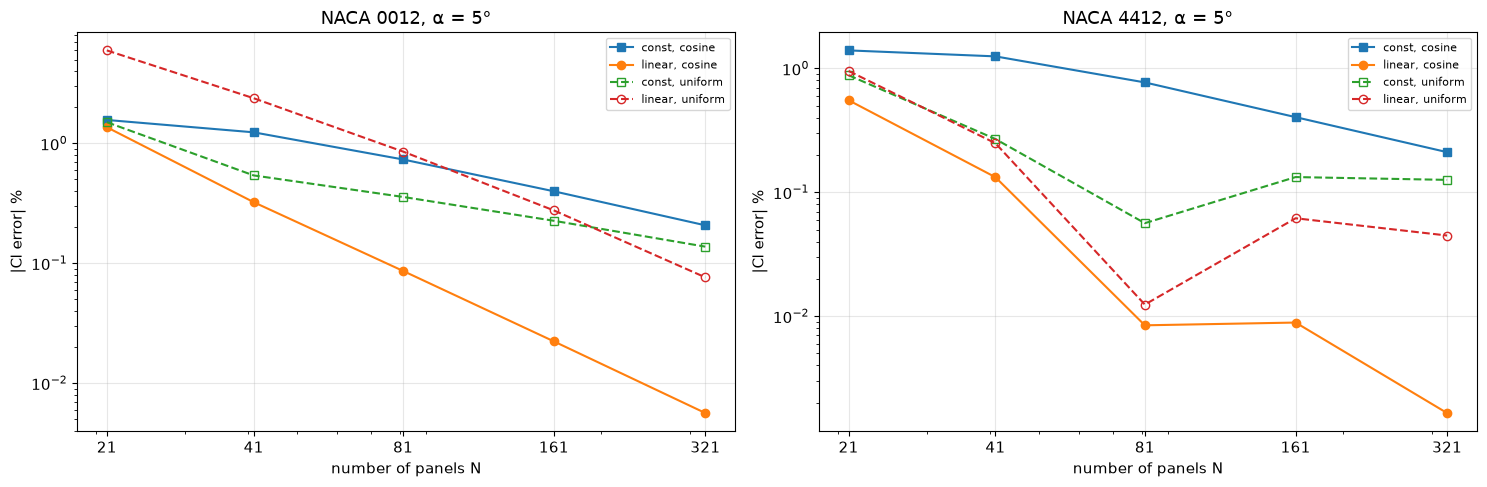

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
print(f"{'airfoil':8s}{'spacing':9s}{'N':>5s}{'const Cl':>10s}{'linear Cl':>11s}")
for k, code_ in enumerate(["0012", "4412"]):
    for sp, ls in [("cosine", "-"), ("uniform", "--")]:
        for mname, f in methods:
            errs = []
            for N in Ns_a:
                r = f(*naca4_geometry(code_, N, sp), ALPHA)
                errs.append(abs(r["Cl"] - ref[code_]["Cl"]) / ref[code_]["Cl"] * 100)
            ax[k].loglog(Ns_a, errs, ls, marker="o" if mname == "linear" else "s",
                         mfc="none" if sp == "uniform" else None, label=f"{mname}, {sp}")
    for N in [21, 81, 321]:
        xb, yb = naca4_geometry(code_, N, "uniform")
        print(f"{code_:8s}{'uniform':9s}{N:5d}{vortex_panel_method_0(xb, yb, ALPHA)['Cl']:10.4f}"
              f"{vortex_panel_method_1(xb, yb, ALPHA)['Cl']:11.4f}")
    label_N(ax[k], Ns_a)
    ax[k].set(xlabel="number of panels N", ylabel="|Cl error| %", title=f"NACA {code_}, α = 5°"); ax[k].legend(fontsize=8)
plt.tight_layout(); plt.show()

   N   largest |Cp|, plain least squares    largest |Cp|, method 0 (rcond=1e-3)
  40                                 7.2                                    1.8
  41                                 2.1                                    1.8
  80                                16.6                                    1.8
  81                                 1.8                                    1.8
 160                                12.1                                    1.8
 161                                 1.8                                    1.8


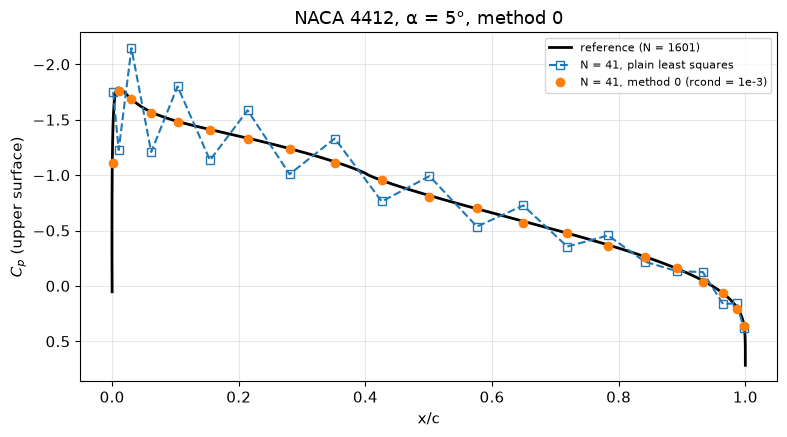

In [16]:
# Why method 0 uses rcond=1e-3: plain least squares vs. method 0 (NACA 4412, 5 deg)
def method0_plain_lstsq(xb, yb, alpha_deg):
    # Same as vortex_panel_method_0 but WITHOUT the cut-off (rcond=None keeps the zig-zag mode)
    a = np.radians(alpha_deg)
    pan, Cn1, Cn2, Ct1, Ct2 = influence(xb, yb)
    N = len(pan["S"])
    A = np.vstack([Cn1 + Cn2, np.eye(N)[0] + np.eye(N)[-1]])
    b = np.append(np.sin(pan["theta"] - a), 0.0)
    g = np.linalg.lstsq(A, b, rcond=None)[0]
    return 1 - (np.cos(pan["theta"] - a) + (Ct1 + Ct2) @ g)**2

print(f"{'N':>4}  {'largest |Cp|, plain least squares':>34}  {'largest |Cp|, method 0 (rcond=1e-3)':>37}")
for N in [40, 41, 80, 81, 160, 161]:
    xb, yb = naca4_geometry("4412", N)
    print(f"{N:4d}  {np.abs(method0_plain_lstsq(xb, yb, ALPHA)).max():34.1f}  "
          f"{np.abs(vortex_panel_method_0(xb, yb, ALPHA)['Cp']).max():37.1f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
xb, yb = naca4_geometry("4412", 41); h = 20
r0 = vortex_panel_method_0(xb, yb, ALPHA); cp_plain = method0_plain_lstsq(xb, yb, ALPHA)
xr, yr = naca4_geometry("4412", 1601)
ax.plot(xr[800:-1], ref["4412"]["Cp_nodes"][800:-1], "k-", lw=2, label="reference (N = 1601)")
ax.plot(r0["xc"][h:], cp_plain[h:], "s--", mfc="none", label="N = 41, plain least squares")
ax.plot(r0["xc"][h:], r0["Cp"][h:], "o", label="N = 41, method 0 (rcond = 1e-3)")
ax.invert_yaxis(); ax.set(xlabel="x/c", ylabel="$C_p$ (upper surface)", title="NACA 4412, α = 5°, method 0"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4.3 Result discussion for airfoils
- **Number of panels:** both methods converge. With cosine spacing the linear method converges at about **second order** (NACA 0012 lift error $0.32\%$, $0.086\%$, $0.022\%$ at $N=41,81,161$), the constant method only at about **first order** ($1.24\%$, $0.74\%$, $0.40\%$). Both are within about $1.6\%$ of the reference already at $N=21$.
- **Pressure:** away from the leading edge, $C_p$ is close to the reference already for $N\approx41$–$81$. The leading-edge suction peak and the last few percent of chord near the trailing edge are the hardest regions to resolve.
- **Panel distribution:** cosine spacing is clearly better. For the linear method on NACA 0012 at $N=21$ the lift error is $1.4\%$ with cosine spacing against $6\%$ with uniform spacing. Uniform spacing puts very few panels around the strongly curved leading edge, where the pressure changes fastest. For the constant method with uniform spacing the error does not decrease steadily with $N$, so convergence cannot be trusted. **Where the panels are placed matters more than how many there are.**
- **Zig-zag mode of method 0:** with plain least squares, method 0 gives large varatopn of $C_p$ values for even $N$ (largest $|C_p|=7.2$ at $N=40$ and $16.6$ at $N=80$, instead of $1.8$) and a visible zig-zag at $N=41$. The cut-off `rcond=1e-3` removes this mode and gives a smooth $C_p$ for any $N$. A mild zig-zag is still visible at the very coarse $N=21$, where the mode is not small enough to be cut off; it disappears as $N$ grows.
- **$C_l$ check:** $C_l\approx0$ for NACA 0012 at $\alpha=0^\circ$ and a positive $C_l$ for NACA 4412 at $\alpha=0^\circ$, as expected.

# 5. Prediction of airfoil characteristics
Both functions are used with $N=161$ cosine-spaced panels to predict, for NACA 0012 and NACA 4412:
- the lift curve $C_l(\alpha)$, the lift-curve slope and the zero-lift angle $\alpha_{L0}$;
- the quarter-chord moment $C_{m,c/4}$
- the pressure-coefficient distributions.

The results are compared with **thin-airfoil theory**: $dC_l/d\alpha=2\pi$ per radian, $\alpha_{L0}=0$ for a symmetric airfoil, and for the NACA 4412 mean line $\alpha_{L0}\approx-4.15^\circ$ and $C_{m,c/4}\approx-0.106$ (_Anderson_). The thickness-corrected slope $2\pi(1+0.77\,t/c)$ is also shown.

In [20]:
N = 161
alphas = np.arange(-8.0, 13.0, 1.0)
airfoils = ["0012", "4412"]
data = {}
for code_ in airfoils:
    xb, yb = naca4_geometry(code_, N)
    for key, f in [("m0", vortex_panel_method_0), ("m1", vortex_panel_method_1)]:
        res = [f(xb, yb, a) for a in alphas]
        data[(code_, key)] = (np.array([r["Cl"] for r in res]), np.array([r["Cm"] for r in res]))

print(f"{'airfoil':8s}{'method':8s}{'Cl_alpha (/rad)':>16s}{'(/deg)':>8s}{'alpha_L0 (deg)':>16s}{'Cl(0)':>8s}{'Cm_c/4 (0)':>12s}")
for code_ in airfoils:
    for key in ("m0", "m1"):
        Cl, Cm = data[(code_, key)]
        slope, icpt = np.polyfit(np.radians(alphas), Cl, 1)
        print(f"{code_:8s}{key:8s}{slope:16.3f}{slope*np.pi/180:8.4f}{-np.degrees(icpt/slope):16.2f}"
              f"{Cl[alphas == 0][0]:8.4f}{Cm[alphas == 0][0]:12.4f}")
print(f"\nthin-airfoil theory: Cl_alpha = 2*pi = {2*np.pi:.3f} /rad;  "
      f"thickness-corrected 2*pi*(1 + 0.77 t/c) = {2*np.pi*(1 + 0.77*0.12):.3f} /rad for t/c = 12 %")

airfoil method   Cl_alpha (/rad)  (/deg)  alpha_L0 (deg)   Cl(0)  Cm_c/4 (0)
0012    m0                 6.920  0.1208            0.00 -0.0001      0.0000
0012    m1                 6.891  0.1203            0.00  0.0002     -0.0000
4412    m0                 6.902  0.1205           -4.29  0.5201     -0.1106
4412    m1                 6.871  0.1199           -4.30  0.5182     -0.1106

thin-airfoil theory: Cl_alpha = 2*pi = 6.283 /rad;  thickness-corrected 2*pi*(1 + 0.77 t/c) = 6.864 /rad for t/c = 12 %


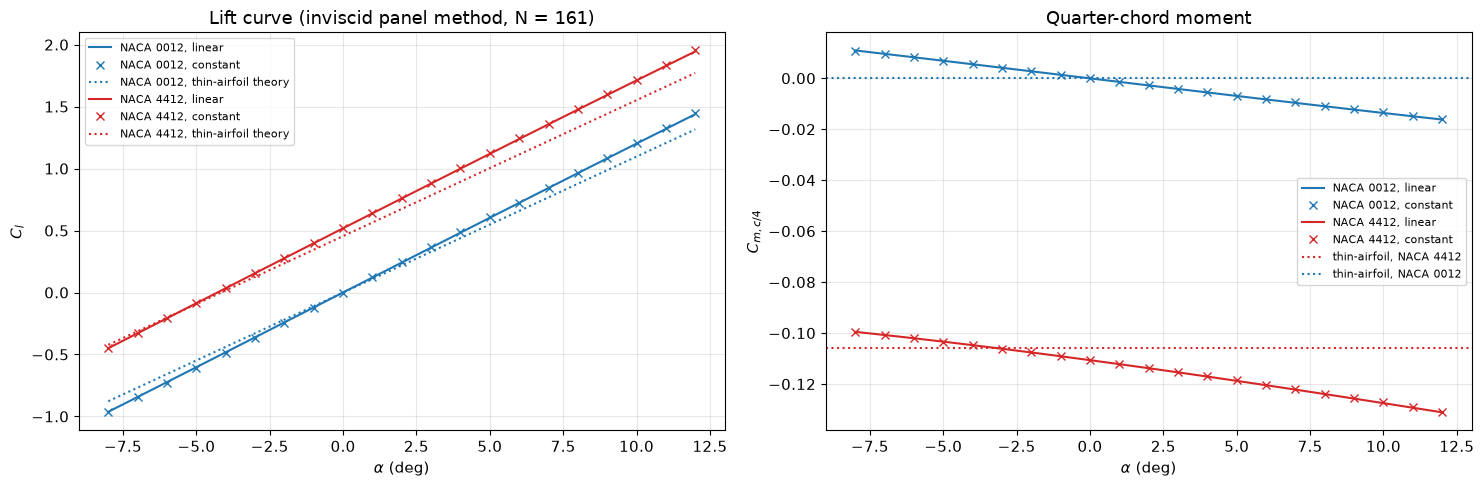

In [21]:
thin_aL0 = {"0012": 0.0, "4412": -4.15}
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for code_, col in zip(airfoils, ["tab:blue", "tab:red"]):
    Cl1, Cm1 = data[(code_, "m1")]; Cl0, Cm0 = data[(code_, "m0")]
    ax[0].plot(alphas, Cl1, "-", color=col, label=f"NACA {code_}, linear")
    ax[0].plot(alphas, Cl0, "x", color=col, ms=6, label=f"NACA {code_}, constant")
    ax[0].plot(alphas, 2*np.pi*np.radians(alphas - thin_aL0[code_]), ":", color=col, label=f"NACA {code_}, thin-airfoil theory")
    ax[1].plot(alphas, Cm1, "-", color=col, label=f"NACA {code_}, linear")
    ax[1].plot(alphas, Cm0, "x", color=col, ms=6, label=f"NACA {code_}, constant")
ax[1].axhline(-0.106, color="tab:red", ls=":", label="thin-airfoil, NACA 4412")
ax[1].axhline(0.0, color="tab:blue", ls=":", label="thin-airfoil, NACA 0012")
ax[0].set(xlabel=r"$\alpha$ (deg)", ylabel="$C_l$", title=f"Lift curve (inviscid panel method, N = {N})"); ax[0].legend(fontsize=8)
ax[1].set(xlabel=r"$\alpha$ (deg)", ylabel="$C_{m,c/4}$", title="Quarter-chord moment"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

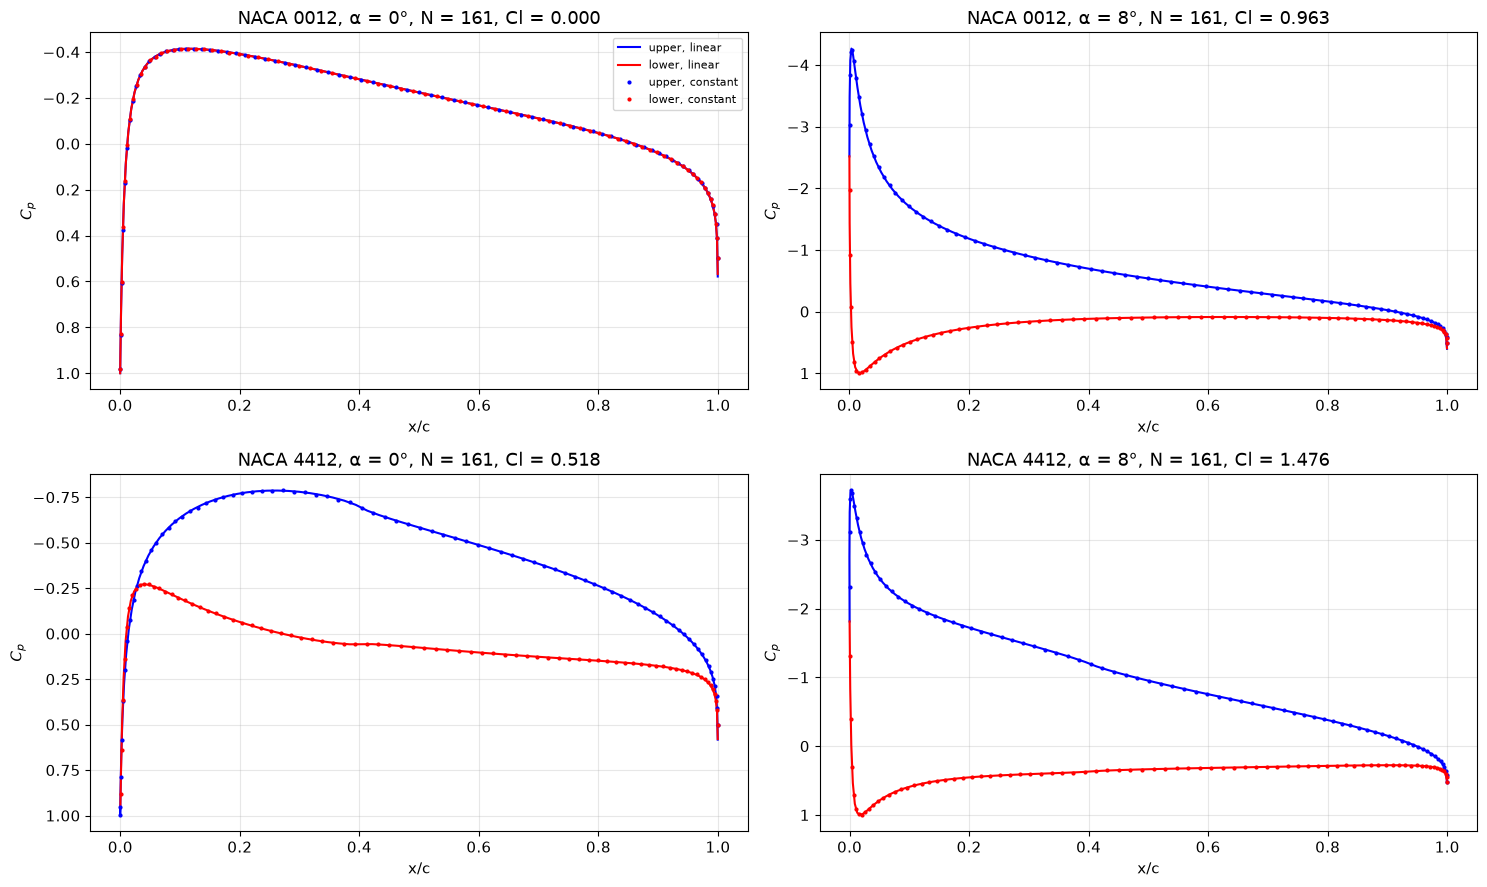

NACA 4412, 8 deg: Cp_min (upper) = -3.716 at x/c = 0.0034,  Cl = 1.4757


In [22]:
# Pressure coefficient distributions with N = 161 (lines: linear method at the nodes; dots: constant method)
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
for row, code_ in enumerate(airfoils):
    xb, yb = naca4_geometry(code_, N)
    h = N//2                                     # first h panels = lower surface
    for col, a in enumerate([0.0, 8.0]):
        r1 = vortex_panel_method_1(xb, yb, a); r0 = vortex_panel_method_0(xb, yb, a)
        A_ = ax[row, col]
        A_.plot(xb[h:-1], r1["Cp_nodes"][h:-1], "b-", label="upper, linear")
        A_.plot(xb[1:h+1], r1["Cp_nodes"][1:h+1], "r-", label="lower, linear")
        A_.plot(r0["xc"][h:], r0["Cp"][h:], "b.", ms=4, label="upper, constant")
        A_.plot(r0["xc"][:h], r0["Cp"][:h], "r.", ms=4, label="lower, constant")
        A_.invert_yaxis()
        A_.set(xlabel="x/c", ylabel="$C_p$", title=f"NACA {code_}, α = {a:.0f}°, N = {N}, Cl = {r1['Cl']:.3f}")
        if row == 0 and col == 0: A_.legend(fontsize=8)
plt.tight_layout(); plt.show()

xb, yb = naca4_geometry("4412", N); h = N//2
r1 = vortex_panel_method_1(xb, yb, 8.0)
k = np.argmin(r1["Cp_nodes"][h:-1])
print(f"NACA 4412, 8 deg: Cp_min (upper) = {r1['Cp_nodes'][h:-1][k]:.3f} at x/c = {xb[h:-1][k]:.4f},  Cl = {r1['Cl']:.4f}")

## 5.1 Result discussion for airfoil characteristics
- **Lift curve:** $C_l(\alpha)$ is a straight line for both airfoils, because the model has no viscosity. The lift-curve slope is $6.89$ /rad (linear) and $6.92$ /rad (constant) for NACA 0012, and $6.87$ /rad for NACA 4412, about $10\%$ above the thin-airfoil value $2\pi=6.28$. The reason is thickness: a thick airfoil speeds up the flow more, and the thickness-corrected estimate $2\pi(1+0.77\,t/c)=6.86$ /rad agrees within $0.5\%$.
- **Effect of camber:** the NACA 0012 curve passes through the origin. Camber shifts the NACA 4412 curve up: $C_l=0.52$ at $\alpha=0^\circ$ and $\alpha_{L0}=-4.3^\circ$, close to the thin-airfoil value $-4.15^\circ$.
- **Moment:** NACA 0012 has $C_{m,c/4}=0$ at $\alpha=0^\circ$; NACA 4412 has a nose-down $C_{m,c/4}=-0.111$, close to the thin-airfoil value $-0.106$. In the panel method $C_{m,c/4}$ becomes slightly more negative as $\alpha$ grows (about $-0.011$ per unit $C_l$), so the inviscid aerodynamic centre is at about $0.26c$ rather than exactly $0.25c$ (a thickness effect).
- **Pressure distributions:** at $\alpha=0^\circ$ the NACA 0012 upper and lower curves are identical (no lift); the NACA 4412 already has lower pressure on the upper surface because of camber. At $\alpha=8^\circ$ a strong suction peak forms right behind the leading edge ($C_{p,\min}=-3.72$ at $x/c=0.003$ for NACA 4412), the stagnation point ($C_p=1$) moves onto the lower surface, and the pressure then recovers along the rest of the chord. The area between the upper and lower curves is the lift.
- **The two methods agree** to within about $0.5\%$ in $C_l$ and $C_m$ at $N=161$.

# 6. Limitations of prediction: effect of thickness
Symmetric NACA 00xx airfoils with $t/c=6\%$ to $30\%$ are computed with the linear method ($N=161$, cosine). Two quantities are followed:
1. the predicted **lift-curve slope**, from $\alpha=0^\circ,2^\circ,4^\circ$;
2. the **adverse pressure gradient** on the rear upper surface at $\alpha=6^\circ$: $\;\big(C_p(x/c=0.9)-C_p(x/c=0.5)\big)/0.4$.

The second quantity shows how hard the boundary layer would have to work against rising pressure in a real (viscous) flow; the panel method itself has no boundary layer.

In [23]:
thick = [6, 9, 12, 15, 18, 21, 24, 30]
slopes, grads = [], []
print(f"{'airfoil':>10}{'Cl_alpha (/rad)':>17}{'ratio to 2pi':>14}{'rear dCp/dx':>13}")
for tt in thick:
    code_ = f"00{tt:02d}"
    xb, yb = naca4_geometry(code_, 161)
    cl = [vortex_panel_method_1(xb, yb, a)["Cl"] for a in (0, 2, 4)]
    slope = np.polyfit(np.radians([0, 2, 4]), cl, 1)[0]
    r = vortex_panel_method_1(xb, yb, 6.0)
    up = slice(80, None)                                   # upper-surface nodes
    c50 = np.interp(0.5, xb[up], r["Cp_nodes"][up]); c90 = np.interp(0.9, xb[up], r["Cp_nodes"][up])
    slopes.append(slope); grads.append((c90 - c50)/0.4)
    print(f"NACA {code_:>5}{slope:17.3f}{slope/(2*np.pi):14.3f}{grads[-1]:13.2f}")

   airfoil  Cl_alpha (/rad)  ratio to 2pi  rear dCp/dx
NACA  0006            6.593         1.049         0.74
NACA  0009            6.753         1.075         0.93
NACA  0012            6.912         1.100         1.13
NACA  0015            7.073         1.126         1.33
NACA  0018            7.234         1.151         1.53
NACA  0021            7.396         1.177         1.74
NACA  0024            7.559         1.203         1.96
NACA  0030            7.888         1.255         2.39


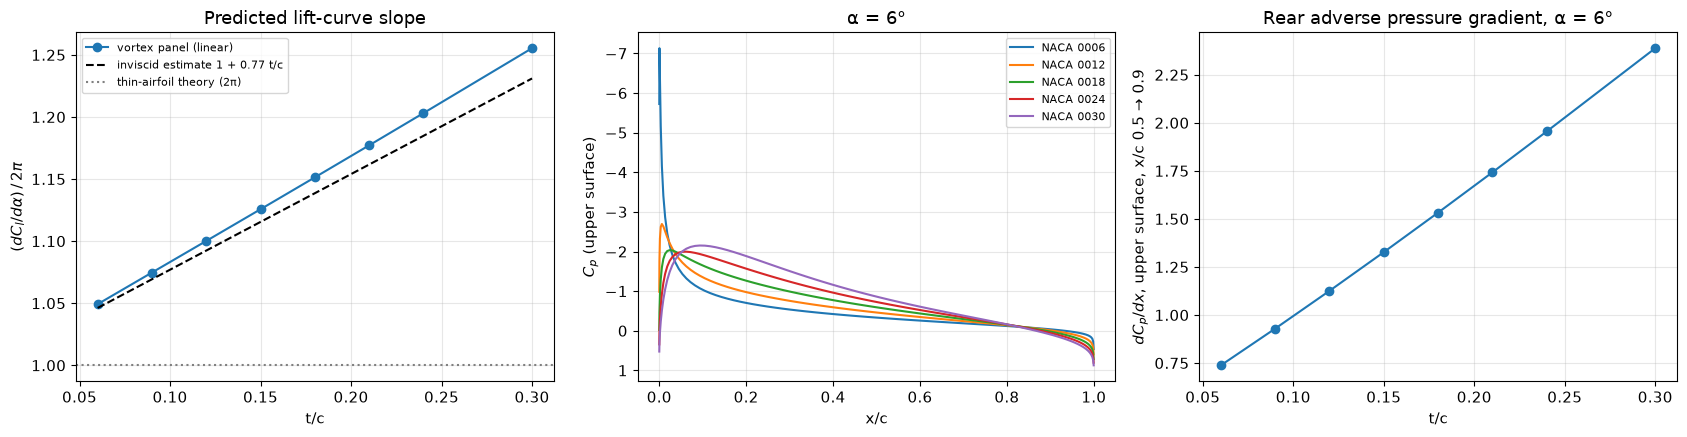

In [24]:
tc = np.array(thick)/100
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(tc, np.array(slopes)/(2*np.pi), "o-", label="vortex panel (linear)")
ax[0].plot(tc, 1 + 0.77*tc, "k--", label="inviscid estimate 1 + 0.77 t/c")
ax[0].axhline(1, color="gray", ls=":", label="thin-airfoil theory (2π)")
ax[0].set(xlabel="t/c", ylabel=r"$(dC_l/d\alpha)\,/\,2\pi$", title="Predicted lift-curve slope"); ax[0].legend(fontsize=8)
for tt in [6, 12, 18, 24, 30]:
    xb, yb = naca4_geometry(f"00{tt:02d}", 161); r = vortex_panel_method_1(xb, yb, 6.0)
    ax[1].plot(xb[80:-1], r["Cp_nodes"][80:-1], label=f"NACA 00{tt:02d}")
ax[1].invert_yaxis(); ax[1].set(xlabel="x/c", ylabel="$C_p$ (upper surface)", title="α = 6°"); ax[1].legend(fontsize=8)
ax[2].plot(tc, grads, "o-")
ax[2].set(xlabel="t/c", ylabel="$dC_p/dx$, upper surface, x/c 0.5 → 0.9", title="Rear adverse pressure gradient, α = 6°")
plt.tight_layout(); plt.show()

## 6.1 Result discussion for thickness effects
- **Prediction vs. reality:** the panel method predicts a lift-curve slope that **keeps rising** with thickness, from $1.05\times2\pi$ for NACA 0006 to $1.26\times2\pi$ for NACA 0030, following the inviscid estimate $2\pi(1+0.77\,t/c)$. Wind-tunnel data show the **opposite**: measured slopes are below $2\pi$ and fall further for sections thicker than about $12$–$15\%$ (_Abbott & von Doenhoff, 1959_). So the gap between prediction and reality grows with thickness.
- **Physical reason:** the rear adverse pressure gradient on the upper surface roughly **triples** from NACA 0006 ($0.74$) to NACA 0030 ($2.39$). In a real flow, a stronger adverse gradient makes the boundary layer thicker and makes it separate earlier near the trailing edge. This effectively reduces the camber and moves the real Kutta condition away from the sharp trailing edge, so the real lift is lower. The panel method has **no boundary layer**, so it cannot see any of this, and it never predicts stall.
- **Remedy:** couple the panel method with a boundary-layer calculation (viscous–inviscid interaction), as in XFOIL (_Drela, 1989_).

# 7. Conclusions
1. Both methods were implemented from the same Kuethe & Chow / Liu (2018) influence coefficients, and the coefficients were checked against direct numerical integration (agreement to 10 digits).
2. On the **cylinder**, both give zero lift and the exact $C_p$. The linear method's nodal $C_p$ converges at third order; Liu's midpoint-velocity $C_p$ converges only at first order.
3. On **airfoils**, The linear method converges faster (about second order in $C_l$, against first order for the constant method), and **cosine spacing** is much better than uniform spacing.
4. The constant-strength method needs care:  zig-zag mode must be removed (here with `rcond=1e-3`), otherwise even $N$ gives wrong pressures.
5. For NACA 0012 and NACA 4412 the predicted $dC_l/d\alpha\approx6.9$ /rad, $\alpha_{L0}$ and $C_{m,c/4}$ agree well with thin-airfoil theory plus a thickness correction.
6. Because the method is inviscid, its predictions get **worse as thickness increases**: it predicts a rising lift slope while real airfoils show a falling one, due to boundary-layer growth and separation that the method cannot model.

# 8. References
1. H. Liu, "Linear Strength Vortex Panel Method for NACA 4412 Airfoil", *IOP Conf. Series: Materials Science and Engineering*, 326, 012016, 2018.
2. A. M. Kuethe and C.-Y. Chow, *Foundations of Aerodynamics: Bases of Aerodynamic Design*, 5th ed., Wiley, 1998.
3. J. Katz and A. Plotkin, *Low-Speed Aerodynamics*, 2nd ed., Cambridge University Press, 2001.
4. J. D. Anderson, *Fundamentals of Aerodynamics*, McGraw-Hill.
5. I. H. Abbott and A. E. von Doenhoff, *Theory of Wing Sections*, Dover, 1959.
6. M. Drela, "XFOIL: An Analysis and Design System for Low Reynolds Number Airfoils", *Lecture Notes in Engineering*, vol. 54, Springer, 1989.

**Acknowledgement of AI use:** AI assistance (Claude, ChatGPT, Google AI mode) was used to help restructure this notebook and to write and debug the vectorised implementation of the influence coefficients and the two solver functions. The formulation was checked against Liu (2018) and the exact cylinder solution, and the influence coefficients were verified against direct numerical quadrature. I have reviewed the code and the results, and I am responsible for the content of this report.

**Discussions:** I had regular discussions with classmates, in and outside class hours, on how to plot the panels for each case, how to plot the airfoils, and how the panel vectors change from one airfoil to another.
